# 03 — Latent State Discovery

This notebook fits the pooled TDE-HMM to the preprocessed development
subset and characterizes the resulting latent states.

**Goal:** discover a small set of recurring electrophysiological states
from the cleaned EEG alone — no task labels at any point — and describe
their temporal structure.

**What we'll do:**
1. Load preprocessed derivatives and cut each trial to its task window
2. Time-delay embed, PCA-reduce, and standardize the pooled representation
3. Select the number of states K by Bayesian Information Criterion
4. Refit the final model on a larger subset with the chosen K
5. Characterize states: transition matrix, occupancy, dwell time
6. Decode each subject and save their state time courses for the next notebook

**Discipline:** experimental labels (load, phase, accuracy, RT) are *not*
used anywhere in this notebook. The state dictionary is defined by EEG
structure alone. Notebook 04 will reveal the labels and test how state
dynamics relate to them.

**Reference method:** Vidaurre et al. (2016, *NeuroImage*) and Vidaurre
et al. (2018, *Nature Communications*) for TDE-HMM; Quinn et al. (2018,
*Frontiers in Neuroscience*) for the pooled multi-subject variant.

In [1]:
# Setup: make src/ importable and load dependencies.

import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from eeg_state import config, model
from eeg_state.io import load_events, reconstruct_trials

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print(f"N_PCS = {config.N_PCS}")
print(f"TDE lags: {config.TDE_LAGS[0]} to {config.TDE_LAGS[-1]} "
      f"({(config.TDE_LAGS[-1] - config.TDE_LAGS[0]) / config.TARGET_SFREQ * 1000:.0f} ms)")
print(f"Target sfreq = {config.TARGET_SFREQ} Hz")
print(f"DEV subjects = {config.DEV_SUBJECTS}")

N_PCS = 20
TDE lags: -7 to 7 (56 ms)
Target sfreq = 250.0 Hz
DEV subjects = ['sub-04', 'sub-05', 'sub-10', 'sub-11', 'sub-17', 'sub-24', 'sub-34', 'sub-45']


## 1. Trial extraction

For each subject we load the preprocessed `.fif` from
`data/derivatives/<subject>/` and cut a fixed window from each trial's
encoding onset. The window is 5.0 s, covering encoding (1.5 s), retention
(2.0 s), and retrieval (1.5 s) — the full stimulus-bound period of the
task. Responses occur after retrieval onset and vary in latency; the
button-press motor event is brief and does not dominate the state
structure, so we include the retrieval period to keep the phase comparison
meaningful in notebook 04.

At 250 Hz this gives 1250 samples per trial. After TDE trimming (±7 samples),
each trial contributes 1236 samples to the model.

In [2]:
TRIAL_DURATION_S = 5.0

def extract_trials(subject: str, duration_s: float = TRIAL_DURATION_S):
    """Return a list of (n_channels, n_times) arrays, one per valid trial.

    A trial is skipped if its window extends past the recording end.
    All trials are used regardless of response correctness: state discovery
    is unsupervised and must not be conditioned on behavior.
    """
    fif = config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif"
    if not fif.exists():
        raise FileNotFoundError(f"{fif} not found; run batch_preprocess first")
    raw = mne.io.read_raw_fif(fif, preload=True, verbose="ERROR")
    sfreq = raw.info["sfreq"]
    data = raw.get_data()
    trials_df = reconstruct_trials(load_events(subject))

    n_samples = int(duration_s * sfreq)
    trials = []
    for _, t in trials_df.iterrows():
        start = int(t["encoding_onset_s"] * sfreq)
        end = start + n_samples
        if end <= data.shape[1]:
            trials.append(data[:, start:end])
    return trials, sfreq

# Sanity check on one subject.
trials_04, sfreq = extract_trials("sub-04")
print(f"sub-04: {len(trials_04)} trials, each {trials_04[0].shape}")
print(f"sfreq = {sfreq} Hz")
print(f"trial duration = {trials_04[0].shape[1] / sfreq:.2f} s")

sub-04: 197 trials, each (63, 1250)
sfreq = 250.0 Hz
trial duration = 5.00 s


## 2. Pooled representation

For every trial we apply time-delay embedding (`±7` samples ≈ 56 ms), then
concatenate across subjects and trials, fit PCA on the pooled data, and
standardize. Standardization is essential for numerical stability: the
raw PCA time courses of volt-scale EEG have variances around 10⁻⁸, which
causes the full-covariance Gaussian emission model to fail Cholesky
decomposition (as we discovered during testing).

The pooled model produces **one shared state dictionary** across all
subjects. This is the standard group-level TDE-HMM approach (Quinn et al.
2018), and it makes downstream load/phase comparisons directly comparable
across subjects.

In [3]:
# Subset sizes. K selection is compute-bound; we use fewer trials there
# and refit the final model on a larger subset once K is fixed.
N_TRIALS_K_SELECT = 20   # per subject
N_TRIALS_FINAL = 50      # per subject

def build_subset(n_per_subject: int) -> dict:
    """Return {subject: [trial_arrays]} with n_per_subject trials each.

    Trials are taken in presentation order (no shuffling) so that the
    subset selection is deterministic and independent of random seed.
    """
    subset = {}
    for sub in config.DEV_SUBJECTS:
        trials, _ = extract_trials(sub)
        subset[sub] = trials[:n_per_subject]
    return subset

subset_k = build_subset(N_TRIALS_K_SELECT)
total_trials = sum(len(t) for t in subset_k.values())
print(f"K-selection subset: {total_trials} trials across {len(subset_k)} subjects")
for sub, trials in subset_k.items():
    print(f"  {sub}: {len(trials)} trials")

K-selection subset: 160 trials across 8 subjects
  sub-04: 20 trials
  sub-05: 20 trials
  sub-10: 20 trials
  sub-11: 20 trials
  sub-17: 20 trials
  sub-24: 20 trials
  sub-34: 20 trials
  sub-45: 20 trials


In [4]:
X_pooled, lengths, pca = model.prepare_pooled_data(subset_k)

print(f"X_pooled shape (samples x features): {X_pooled.shape}")
print(f"lengths: {len(lengths)} trials, total {sum(lengths)} samples")
print(f"mean per feature: {X_pooled.mean(axis=0).mean():.2e}")
print(f"std per feature (min / max): {X_pooled.std(axis=0).min():.3f} / {X_pooled.std(axis=0).max():.3f}")
print(f"PCA explained variance (first 5 PCs): {pca.explained_variance_ratio_[:5].round(3)}")
print(f"PCA cumulative variance at {config.N_PCS} PCs: {pca.explained_variance_ratio_.sum():.3f}")

X_pooled shape (samples x features): (197760, 20)
lengths: 160 trials, total 197760 samples
mean per feature: 8.55e-18
std per feature (min / max): 1.000 / 1.000
PCA explained variance (first 5 PCs): [0.266 0.133 0.081 0.059 0.041]
PCA cumulative variance at 20 PCs: 0.783


## 3. Number of states — BIC

We fit models with K in {4, 6, 8} and compare Bayesian Information
Criterion:

$$\text{BIC}(K) = -2 \cdot \text{LL}(K) + p(K) \cdot \log(n)$$

where LL is the training log-likelihood returned by Baum–Welch, n is the
total number of samples, and p(K) is the number of free parameters:

- K·D for the means
- K·D(D+1)/2 for the full covariances
- K(K−1) for the transition matrix
- (K−1) for the initial state distribution

Lower BIC is better. The Vidaurre TDE-HMM papers use cross-validated
variational free energy for K selection; BIC is the standard
information-criterion proxy when the model is fit by maximum likelihood
rather than variational inference, and it does not require held-out data.

Given the computation budget, we use a reduced iteration count during K selection
(50 instead of 200) — the log-likelihood plateau is normally reached well
before iteration 50 on standardized data.

In [5]:
K_GRID = [4, 6, 8]

def count_parameters(K: int, D: int) -> int:
    return K * D + K * D * (D + 1) // 2 + K * (K - 1) + (K - 1)

n_samples = X_pooled.shape[0]
n_features = X_pooled.shape[1]

results = []
for K in K_GRID:
    print(f"K = {K} ...")
    fitted = model.fit_hmm(
        X_pooled, lengths, n_states=K, n_iter=50, random_state=config.RANDOM_SEED,
    )
    ll = fitted.score(X_pooled, lengths=lengths)
    p = count_parameters(K, n_features)
    bic = -2 * ll + p * np.log(n_samples)
    aic = -2 * ll + 2 * p
    results.append({
        "K": K, "log_lik": ll, "n_params": p, "BIC": bic, "AIC": aic,
        "converged_iter": fitted.monitor_.iter,
        "converged": fitted.monitor_.converged,
    })
    print(f"  log_lik={ll:.2e}  p={p}  BIC={bic:.2e}  "
          f"iter={fitted.monitor_.iter}  converged={fitted.monitor_.converged}")

results_df = pd.DataFrame(results)
print("\n" + results_df.to_string(index=False))

K = 4 ...
  log_lik=-4.60e+06  p=935  BIC=9.21e+06  iter=50  converged=True
K = 6 ...
  log_lik=-4.54e+06  p=1415  BIC=9.10e+06  iter=50  converged=True
K = 8 ...
  log_lik=-4.40e+06  p=1903  BIC=8.82e+06  iter=50  converged=True

 K       log_lik  n_params          BIC          AIC  converged_iter  converged
 4 -4.599010e+06       935 9.209423e+06 9.199891e+06              50       True
 6 -4.543015e+06      1415 9.103286e+06 9.088860e+06              50       True
 8 -4.399005e+06      1903 8.821217e+06 8.801816e+06              50       True


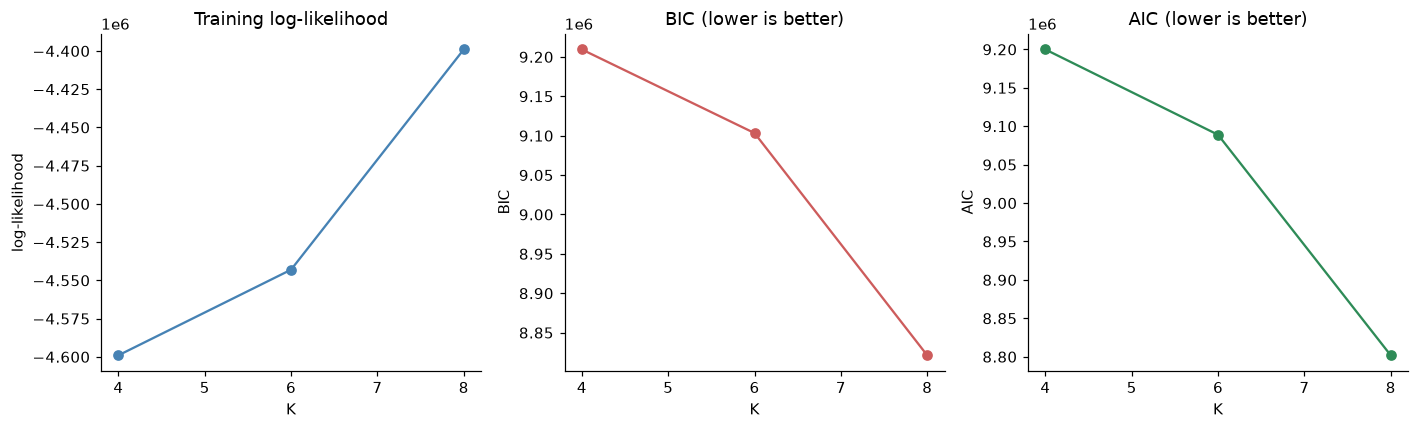

Best K by BIC: 8
Best K by AIC: 8


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].plot(results_df["K"], results_df["log_lik"], "o-", color="steelblue")
axes[0].set_xlabel("K"); axes[0].set_ylabel("log-likelihood")
axes[0].set_title("Training log-likelihood")

axes[1].plot(results_df["K"], results_df["BIC"], "o-", color="indianred")
axes[1].set_xlabel("K"); axes[1].set_ylabel("BIC")
axes[1].set_title("BIC (lower is better)")

axes[2].plot(results_df["K"], results_df["AIC"], "o-", color="seagreen")
axes[2].set_xlabel("K"); axes[2].set_ylabel("AIC")
axes[2].set_title("AIC (lower is better)")

plt.tight_layout(); plt.show()

best_k_bic = int(results_df.loc[results_df["BIC"].idxmin(), "K"])
best_k_aic = int(results_df.loc[results_df["AIC"].idxmin(), "K"])
print(f"Best K by BIC: {best_k_bic}")
print(f"Best K by AIC: {best_k_aic}")

**Interpretation of the plot.** If BIC and AIC disagree, or if both
monotonically decrease across the grid, the grid is too narrow or the
data are not constraining K well. In that case we fall back to the
smaller of the two choices and note the ambiguity in the README rather
than expanding the grid indefinitely.

Whatever K the criterion picks, we now refit on a larger subset
(more trials per subject) with the chosen K and higher iteration count.
The final model is what gets used downstream.

In [7]:
K_CHOSEN = best_k_bic   # override manually if BIC/AIC disagree and you prefer the other
print(f"Using K = {K_CHOSEN} for the final model")

subset_final = build_subset(N_TRIALS_FINAL)
total_final = sum(len(t) for t in subset_final.values())
print(f"Final subset: {total_final} trials across {len(subset_final)} subjects")

X_final, lengths_final, pca_final = model.prepare_pooled_data(subset_final)
print(f"X_final shape: {X_final.shape}")

hmm_final = model.fit_hmm(
    X_final, lengths_final, n_states=K_CHOSEN, n_iter=200,
    random_state=config.RANDOM_SEED,
)
print(f"Final model converged: {hmm_final.monitor_.converged} "
      f"after {hmm_final.monitor_.iter} iterations")
print(f"Final log-likelihood: {hmm_final.score(X_final, lengths=lengths_final):.4e}")

Using K = 8 for the final model
Final subset: 400 trials across 8 subjects
X_final shape: (494400, 20)
Final model converged: True after 81 iterations
Final log-likelihood: -7.8548e+06


## 4. Persist model artifacts

The fitted HMM, PCA transform, and standardization parameters are saved
together as a single pickle in `results/models/`. This is what notebook 04
loads to decode new trials or re-derive state time courses without
refitting.

In [8]:
artifacts_dir = config.RESULTS / "models"
artifacts_dir.mkdir(parents=True, exist_ok=True)
artifacts_path = artifacts_dir / "tde_hmm_model.pkl"

artifacts = {
    "hmm": hmm_final,
    "pca": pca_final,
    "mean": X_final.mean(axis=0, keepdims=True),
    "std": X_final.std(axis=0, keepdims=True),
    "n_states": K_CHOSEN,
    "n_pcs": config.N_PCS,
    "tde_lags": config.TDE_LAGS,
    "trial_duration_s": TRIAL_DURATION_S,
    "target_sfreq": config.TARGET_SFREQ,
    "dev_subjects": config.DEV_SUBJECTS,
    "n_trials_final": N_TRIALS_FINAL,
}
with open(artifacts_path, "wb") as f:
    pickle.dump(artifacts, f)
print(f"Saved -> {artifacts_path}")

Saved -> D:\Research\eeg-neural-state-dynamics\results\models\tde_hmm_model.pkl


## 5. State characterization

Three views of the fitted state dictionary.

**Transition matrix.** The probability of moving from state i to state j
on any given sample. Diagonal entries are self-transition probabilities;
large diagonals mean states persist. Off-diagonal structure tells us
which states are neighbours in the state space.

**Occupancy.** The fraction of total time each state is active. Across
all subjects and trials, this should sum to 1.

**Dwell time.** For each time a state becomes active, how long does it
stay active before switching? Measured in milliseconds. Distributions
are typically heavy-tailed (most visits are brief, a few last long).

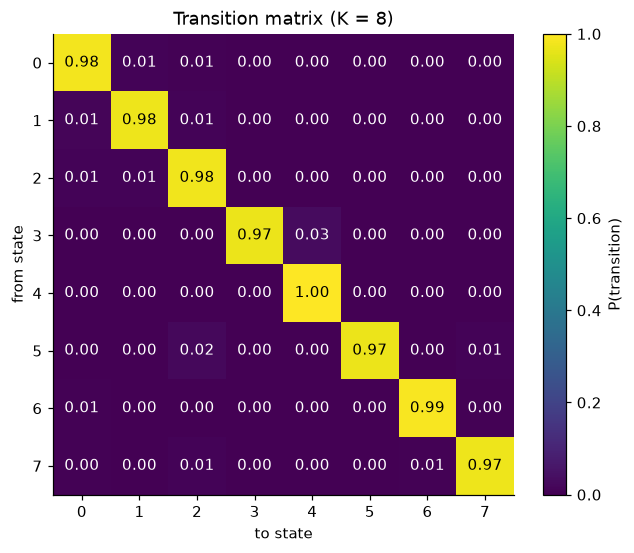

Self-transition probabilities (diagonal):
  state 0: 0.983
  state 1: 0.976
  state 2: 0.979
  state 3: 0.971
  state 4: 0.996
  state 5: 0.970
  state 6: 0.989
  state 7: 0.975


In [9]:
viterbi_final, posteriors_final = model.get_state_time_course(
    hmm_final, X_final, lengths_final,
)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(hmm_final.transmat_, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(K_CHOSEN)); ax.set_yticks(range(K_CHOSEN))
ax.set_xlabel("to state"); ax.set_ylabel("from state")
ax.set_title(f"Transition matrix (K = {K_CHOSEN})")
for i in range(K_CHOSEN):
    for j in range(K_CHOSEN):
        ax.text(j, i, f"{hmm_final.transmat_[i, j]:.2f}",
                ha="center", va="center",
                color="white" if hmm_final.transmat_[i, j] < 0.5 else "black")
plt.colorbar(im, ax=ax, label="P(transition)")
plt.tight_layout(); plt.show()

print("Self-transition probabilities (diagonal):")
for i in range(K_CHOSEN):
    print(f"  state {i}: {hmm_final.transmat_[i, i]:.3f}")

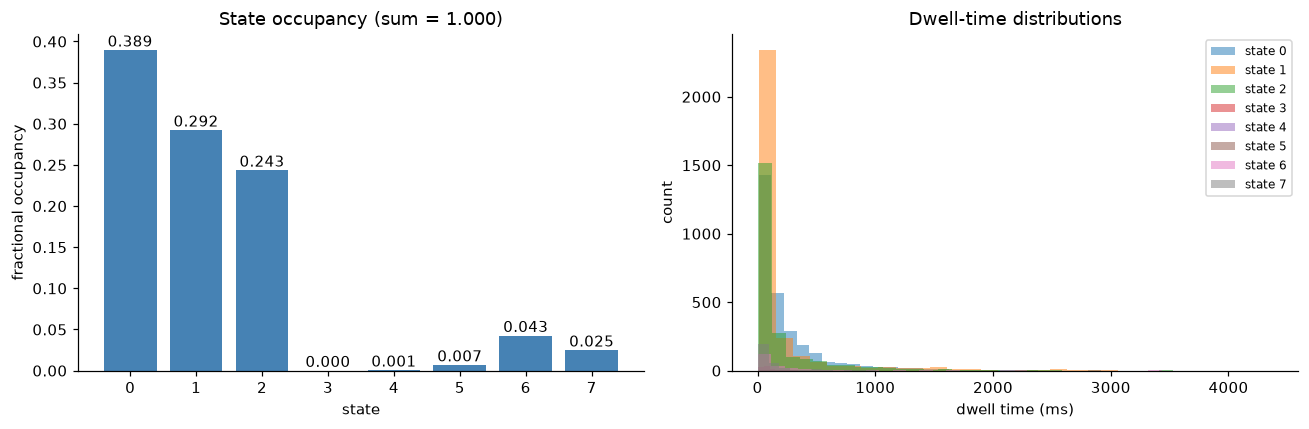

Median dwell times (ms):
  state 0: n_visits=2969, median=120 ms, mean=259 ms
  state 1: n_visits=2993, median=60 ms, mean=193 ms
  state 2: n_visits=2270, median=72 ms, mean=212 ms
  state 3: n_visits=1, median=136 ms, mean=136 ms
  state 4: n_visits=2, median=530 ms, mean=530 ms
  state 5: n_visits=99, median=76 ms, mean=137 ms
  state 6: n_visits=237, median=104 ms, mean=355 ms
  state 7: n_visits=307, median=64 ms, mean=160 ms


In [10]:
# Occupancy: fraction of samples in each state.
occupancy = np.bincount(viterbi_final, minlength=K_CHOSEN) / len(viterbi_final)

# Dwell times: length of each contiguous run of the same state.
# Trials reset dwell measurement (Viterbi path is already per-trial
# because we passed lengths to get_state_time_course).
dwell_ms = {k: [] for k in range(K_CHOSEN)}
start = 0
for L in lengths_final:
    seg = viterbi_final[start:start + L]
    if len(seg) == 0:
        start += L
        continue
    # find run boundaries within this trial
    changes = np.where(np.diff(seg) != 0)[0] + 1
    boundaries = np.concatenate([[0], changes, [len(seg)]])
    for a, b in zip(boundaries[:-1], boundaries[1:]):
        dwell_ms[int(seg[a])].append((b - a) / config.TARGET_SFREQ * 1000)
    start += L

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(K_CHOSEN), occupancy, color="steelblue")
axes[0].set_xticks(range(K_CHOSEN))
axes[0].set_xlabel("state"); axes[0].set_ylabel("fractional occupancy")
axes[0].set_title(f"State occupancy (sum = {occupancy.sum():.3f})")
for i, v in enumerate(occupancy):
    axes[0].text(i, v, f"{v:.3f}", ha="center", va="bottom")

for k in range(K_CHOSEN):
    axes[1].hist(dwell_ms[k], bins=30, alpha=0.5, label=f"state {k}")
axes[1].set_xlabel("dwell time (ms)"); axes[1].set_ylabel("count")
axes[1].set_title("Dwell-time distributions")
axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

print("Median dwell times (ms):")
for k in range(K_CHOSEN):
    if dwell_ms[k]:
        print(f"  state {k}: n_visits={len(dwell_ms[k])}, "
              f"median={np.median(dwell_ms[k]):.0f} ms, "
              f"mean={np.mean(dwell_ms[k]):.0f} ms")

**Spatial characterization.** Full state topographies require projecting
each state's PCA mean back through the TDE window and inverse PCA to
channel space. This is a non-trivial reconstruction and belongs with the
state characterization in notebook 04, where it can be shown alongside
load/phase effects. For now we note that the state means are stored in
`hmm_final.means_` and can be reconstructed later.

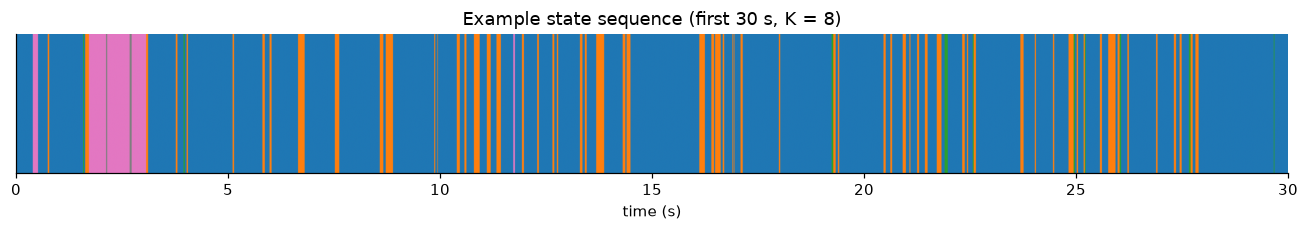

Legend: color corresponds to state index (0-indexed).


In [11]:
# Example: state time course for the first 30 s of concatenated trials.
fig, ax = plt.subplots(figsize=(12, 2.2))
show_samples = int(30 * config.TARGET_SFREQ)
segment = viterbi_final[:show_samples]
ax.imshow(
    segment[np.newaxis, :], aspect="auto", cmap="tab10",
    vmin=0, vmax=max(9, K_CHOSEN - 1), extent=[0, 30, 0, 1],
)
ax.set_xlabel("time (s)"); ax.set_yticks([])
ax.set_title(f"Example state sequence (first 30 s, K = {K_CHOSEN})")
plt.tight_layout(); plt.show()

print("Legend: color corresponds to state index (0-indexed).")

## 6. Decode every subject and save state time courses

For each subject in the development subset, we extract trials, apply the
same TDE + PCA + standardization transform, and decode with the fitted
HMM. The Viterbi path, posteriors, and per-trial lengths are saved to
`data/derivatives/<subject>/<subject>_states.npz` for notebook 04.

Crucially, we decode **all available trials** per subject (not just the
50 used for the final fit), so the downstream load/phase/RT analysis has
the full statistical power of each participant's data.

In [12]:
def decode_subject(subject: str, artifacts: dict) -> dict:
    """Decode all valid trials of one subject using the fitted model."""
    trials, sfreq = extract_trials(subject)
    embeddings = [model.time_delay_embed(t, lags=artifacts["tde_lags"])
                  for t in trials]
    lengths = [e.shape[1] for e in embeddings]
    X = np.concatenate(embeddings, axis=1).T
    X_pca = artifacts["pca"].transform(X)
    X_std = (X_pca - artifacts["mean"]) / artifacts["std"]
    viterbi, posteriors = model.get_state_time_course(
        artifacts["hmm"], X_std, lengths,
    )
    return {
        "viterbi": viterbi,
        "posteriors": posteriors,
        "lengths": np.array(lengths),
        "trial_indices": np.arange(len(trials)),
        "sfreq": sfreq,
    }

for sub in config.DEV_SUBJECTS:
    decoded = decode_subject(sub, artifacts)
    out_path = config.DATA_DERIV / sub / f"{sub}_states.npz"
    np.savez_compressed(
        out_path,
        viterbi=decoded["viterbi"],
        posteriors=decoded["posteriors"],
        lengths=decoded["lengths"],
        trial_indices=decoded["trial_indices"],
        sfreq=decoded["sfreq"],
    )
    print(f"  {sub}: {len(decoded['lengths'])} trials, "
          f"{int(decoded['lengths'].sum())} samples -> {out_path}")

  sub-04: 197 trials, 243492 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-04\sub-04_states.npz
  sub-05: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-05\sub-05_states.npz
  sub-10: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-10\sub-10_states.npz
  sub-11: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-11\sub-11_states.npz
  sub-17: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-17\sub-17_states.npz
  sub-24: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-24\sub-24_states.npz
  sub-34: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-34\sub-34_states.npz
  sub-45: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-45\sub-45_states.npz


## Summary

We have fitted a pooled TDE-HMM to the development subset and saved the
resulting state time courses for every subject.

**What was done:**
- Extracted 5-second windows from every valid trial of every dev subject
- Applied TDE (lags ±7 samples ≈ 56 ms), PCA (20 components), and standardization
- Selected K via BIC on a 20-trial-per-subject subset
- Refit the model on 50 trials per subject with the chosen K
- Saved the fitted HMM, PCA, and standardization parameters to `results/models/tde_hmm_model.pkl`
- Decoded every dev subject with all available trials and saved the state time courses

**What this notebook does not do:**
- It does not use load, phase, accuracy, or RT labels at any point
- It does not interpret states as neural generators (sensor-space only)
- It does not test load or phase effects; that is notebook 04

**Next steps:** `notebooks/04_state_characterization.ipynb` reveals the
experimental labels and asks how state occupancy, dwell time, and switching
relate to cognitive load, task phase, and behavioral performance.